# Gabarito — Curva de ruído do LIGO

**Material de apoio ao notebook `intro-5-noise.ipynb`**

Este gabarito responde às três questões da seção **Questões de verificação**. Os cálculos e as figuras utilizam o **mesmo modelo esquemático de ruído** apresentado no notebook. A comparação com a curva real do detector L1, na campanha O3, refere-se ao gráfico já apresentado no material original.

> **Atenção:** o modelo de ruído é apenas ilustrativo. A frequência de maior sensibilidade e a visibilidade de um sinal podem variar conforme o detector, a campanha de observação e o sinal analisado.

## Questão 1 — Em qual frequência o LIGO apresenta maior sensibilidade?

A sensibilidade é maior onde a **densidade espectral de amplitude de ruído (ASD)** é **menor**.

No gráfico com dados da campanha **O3 do detector L1**, apresentado no notebook original, a região de menor ruído encontra-se aproximadamente **entre 100 Hz e 300 Hz** (em uma faixa larga em torno de algumas centenas de hertz). A curva contém também picos estreitos associados a ruídos instrumentais.

Podemos localizar numericamente o mínimo **do modelo esquemático** utilizado no notebook, sem confundi-lo com uma medida exata do detector.

In [1]:
# Reproduzir o mesmo modelo esquemático do notebook original
import numpy as np
import matplotlib.pyplot as plt

freqs = np.arange(10, 2048, dtype=float)
controls = 4e-12 * (1 / freqs**8)
thermal = 3e-23 * (1 / freqs**0.5)
shot = 3.5e-24 * np.sqrt(1 + (freqs / 500)**2)
cartoon_asd = np.sqrt(controls**2 + shot**2 + thermal**2)

# Localizar o mínimo do MODELO (não uma medida exata do LIGO)
i_min = np.argmin(cartoon_asd)
f_min = freqs[i_min]
asd_min = cartoon_asd[i_min]

print(f"Frequência de mínimo ruído no modelo: {f_min} Hz")
print(f"ASD mínima do modelo: {asd_min:.3e} 1/√Hz")

Frequência de mínimo ruído no modelo: 209.0 Hz
ASD mínima do modelo: 4.324e-24 1/√Hz


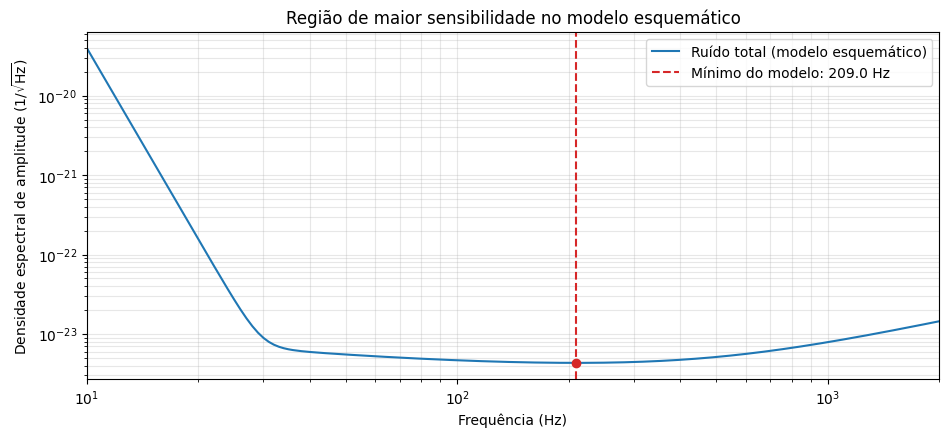

In [2]:
# Visualizar a região de maior sensibilidade do modelo
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.loglog(freqs, cartoon_asd, label='Ruído total (modelo esquemático)')
ax.axvline(f_min, color='tab:red', linestyle='--',
           label=f'Mínimo do modelo: {f_min} Hz')
ax.scatter([f_min], [asd_min], color='tab:red', zorder=3)
ax.set(xlabel='Frequência (Hz)',
       ylabel=r'Densidade espectral de amplitude (1/$\sqrt{\mathrm{Hz}}$)',
       title='Região de maior sensibilidade no modelo esquemático')
ax.set_xlim(10, 2000)
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.show()

**Resposta:** a maior sensibilidade se encontra na região em que a ASD é mais baixa. No **modelo esquemático**, o mínimo ocorre próximo de **209 Hz**. Para os **dados reais O3/L1** apresentados no notebook, a resposta adequada é **aproximadamente 100–300 Hz**, sem atribuir um único valor universal à sensibilidade do LIGO.

---

## Questão 2 — Qual ruído predomina em baixas e altas frequências?

Segundo o **modelo adotado no notebook**:

- **Baixas frequências:** predomina o **ruído de controle**, representado por uma dependência proporcional a \(1/f^8\). O material o utiliza como uma categoria simplificada que reúne várias contribuições.
- **Região intermediária:** o **ruído térmico** pode ter contribuição importante, aproximada por \(1/\sqrt{f}\).
- **Altas frequências:** predomina o **ruído de disparo (*shot noise*)**, associado às flutuações no número de fótons detectados.

Observe essas tendências no gráfico a seguir.

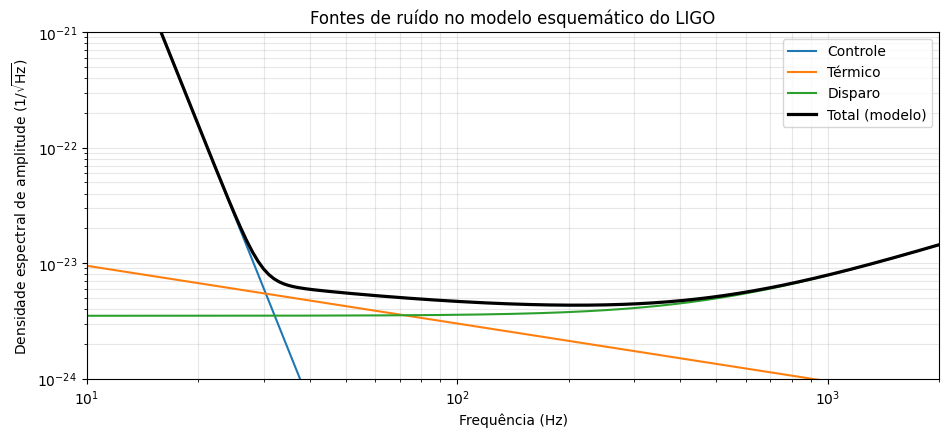

In [3]:
# Comparar as três contribuições e a curva total
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.loglog(freqs, controls, label='Controle')
ax.loglog(freqs, thermal, label='Térmico')
ax.loglog(freqs, shot, label='Disparo')
ax.loglog(freqs, cartoon_asd, color='black', linewidth=2.3,
          label='Total (modelo)')
ax.set(xlabel='Frequência (Hz)',
       ylabel=r'Densidade espectral de amplitude (1/$\sqrt{\mathrm{Hz}}$)',
       title='Fontes de ruído no modelo esquemático do LIGO')
ax.set_xlim(10, 2000)
ax.set_ylim(1e-24, 1e-21)
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.show()

**Resposta:** o **ruído de controle** predomina em baixas frequências e o **ruído de disparo** predomina em altas frequências. Entre esses regimes, a contribuição térmica também é relevante. Essa classificação se refere à decomposição **simplificada** apresentada no notebook.

---

## Questão 3 — Por que observamos apenas a parte final de uma evolução orbital tão longa?

Um sistema binário de buracos negros pode evoluir por milhões ou bilhões de anos até a fusão. Entretanto, o **LIGO é sensível apenas a uma faixa limitada de frequências**, e seu ruído aumenta bastante nas frequências muito baixas.

**Ao longo da evolução do sistema:**

1. **Muito antes da fusão:** a separação entre os objetos é maior, a frequência orbital é baixa e as ondas gravitacionais emitidas também têm frequência baixa. Além disso, a amplitude do sinal é menor. Essas ondas podem estar fora da banda sensível do LIGO ou escondidas pelo ruído.
2. **Durante a aproximação final (*inspiral*):** o sistema perde energia por emissão de ondas gravitacionais; os objetos se aproximam e a frequência orbital aumenta. A frequência da onda gravitacional aumenta junto com sua amplitude: é o sinal conhecido como *chirp*.
3. **Próximo à fusão:** o sinal fica mais intenso e passa por frequências em que o detector pode apresentar melhor sensibilidade. É nessa etapa que ele costuma se destacar sobre o ruído no exemplo do notebook.

### Relação com os gráficos do próprio notebook

O exemplo utiliza uma binária de **10 + 10 massas solares**, com `f_lower = 20 Hz`, `distance = 700` e `fs = 4096 Hz`. O material mostra que a forma de onda isolada se estende, aproximadamente, de **1 s a 7 s** no eixo temporal escolhido. Entretanto, após injetá-la nos **dados reais do L1/O3**, a parte que se destaca no espectrograma corresponde sobretudo ao **trecho final**, aproximadamente o último segundo. O material também indica que, nesse exemplo, o sinal aparece mais nitidamente na região aproximada de **30–200 Hz**.

**Resposta:** a longa duração da evolução orbital não corresponde ao tempo durante o qual o sinal é detectável pelo LIGO. Grande parte da evolução produz ondas com frequência muito baixa ou amplitude insuficiente em relação ao ruído; a etapa final é mais favorável à observação.

> **Importante:** “alguns segundos ou menos” descreve vários sinais de binárias de buracos negros e, em particular, a situação ilustrada aqui. Não é uma regra para todas as fontes: sinais de sistemas menos massivos, como binárias de estrelas de nêutrons, podem permanecer na banda sensível por muito mais tempo.

## Síntese do gabarito

| Questão | Resposta resumida |
|:--|:--|
| 1. Frequência de maior sensibilidade | Onde a ASD é mínima: aproximadamente 100–300 Hz nos dados O3/L1 exibidos; **209 Hz** no modelo esquemático. |
| 2. Fontes dominantes de ruído | **Controle** em baixas frequências; **disparo** em altas frequências; **térmico** contribui na região intermediária. |
| 3. Por que apenas o trecho final é visível? | Antes da fusão, frequência e amplitude são baixas em relação à banda sensível e ao ruído. A aproximação final eleva ambas, favorecendo a observação. |

**Fonte de referência:** notebook `intro-5-noise.ipynb`, inclusive a comparação do modelo com dados do detector L1 na campanha O3.